# Profit and Sensitivity

Finalizes challenge questions 3, 4 and 8 by asking **whether sending is worth it under other margins and costs.** It does not revisit whom to email: lists of the same size cost the same, so costs cancel when they are compared.

The design was fixed in [`DECISIONS.md`](../DECISIONS.md) (2026-11-24) before this notebook was run:

- **No new estimates.** Eight effects already reported are reclassified: the Mens and Womens emails against no email for all customers (stage 01, Welch) and for the three past-purchase audiences (stage 02, HC3).
- **Break-even** is cost per email ÷ margin, at the plan's margins of 30%, 40%, 50% and 60% and costs of \$0.001, \$0.008, \$0.05 and \$0.10. The rule of 2026-11-06 classifies each effect: **worth sending** if the lower end of its 95% interval is above break-even, **uncertain** if only the estimate is, and **not worth sending** otherwise.
- **The base case** (40%, \$0.008, break-even \$0.02) gives the answers. The other combinations show how far they hold.

**This stage cannot be blind.** Every input has already been reported, so most results follow from known numbers by arithmetic. Fixing the rule first prevents choosing the wording after seeing the tables.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import ttest_ind

sys.path.append("..")
from src.prepare import N_TARGET, load_data

MARGINS = [0.30, 0.40, 0.50, 0.60]
COSTS = [0.001, 0.008, 0.05, 0.10]
BASE = (0.40, 0.008)
REVENUE_FIRST = 0.05  # loss accepted in the revenue-first scenario, as a share of incremental spend
SCENARIOS = [(margin, cost) for margin in MARGINS for cost in COSTS]

df = load_data()
break_even = pd.DataFrame({f"{m:.0%} margin": {f"${c:g} per email": c / m for c in COSTS} for m in MARGINS})
distinct = np.unique(np.round(break_even.to_numpy(), 10)).size
print(f"{distinct} different break-even values among {break_even.size} combinations, "
      f"from ${break_even.min().min():.4f} to ${break_even.max().max():.4f}")
break_even.round(4)

15 different break-even values among 16 combinations, from $0.0017 to $0.3333


,30% margin,40% margin,50% margin,60% margin
$0.001 per email,0.0033,0.0025,0.002,0.0017
$0.008 per email,0.0267,0.0200,0.016,0.0133
$0.05 per email,0.1667,0.1250,0.100,0.0833
$0.1 per email,0.3333,0.2500,0.200,0.1667


**Reading the result:** **the 16 combinations give 15 different break-even values, from about \$0.002 to \$0.333 per customer,** because \$0.05 at a 30% margin and \$0.10 at a 60% margin give the same value. Only this ratio matters to the rule, so the analysis below places each effect on this one scale. These values use the assumptions only, not the outcomes.

## Step 1: The eight effects

Recomputed with the methods of stages 01 and 02, and checked against the values reported there.

In [2]:
rows = {}
control = df.loc[df["segment"] == "No E-Mail", "spend"]
for email in ["Mens", "Womens"]:
    treated = df.loc[df["segment"] == f"{email} E-Mail", "spend"]
    ci = ttest_ind(treated, control, equal_var=False).confidence_interval(0.95)
    rows[("All customers", email)] = {"estimate": treated.mean() - control.mean(), "ci_low": ci.low, "ci_high": ci.high}
for audience in ["men's only", "women's only", "both"]:
    fit = smf.ols("spend ~ mens_email + womens_email", df[df["bought"] == audience]).fit(cov_type="HC3")
    for email, term in [("Mens", "mens_email"), ("Womens", "womens_email")]:
        low, high = fit.conf_int().loc[term]
        rows[(f"Bought {audience}", email)] = {"estimate": fit.params[term], "ci_low": low, "ci_high": high}
estimates = pd.DataFrame(rows).T
estimates.index.names = ["customers", "email"]

# The same eight effects as reported in stages 01 and 02 (rounded to the cent there).
reported = [0.77, 0.49, 1.05, 0.42, 0.17, 0.68, 0.68, 0.25, 1.12, 0.28, -0.12, 0.68,
            0.62, 0.27, 0.96, 0.63, 0.30, 0.97, 1.82, 0.49, 3.16, 0.16, -0.81, 1.14]
gap = np.abs(estimates.to_numpy().ravel() - reported).max()
print(f"Largest gap from the reported values: ${gap:.4f}")
estimates.round(3)

Largest gap from the reported values: $0.0050


estimate  ci_low  ci_high
customers           email                            
All customers       Mens       0.770   0.485    1.055
                    Womens     0.424   0.169    0.680
Bought men's only   Mens       0.683   0.247    1.118
                    Womens     0.278  -0.124    0.680
Bought women's only Mens       0.616   0.270    0.962
                    Womens     0.632   0.295    0.968
Bought both         Mens       1.825   0.490    3.160
                    Womens     0.162  -0.814    1.137

**Reading the result:** **the eight effects match those reported in stages 01 and 02,** within the rounding of the reported values to the cent (largest gap \$0.005). Two intervals already reach below zero: the Womens email for buyers of men's only and of both lines.

## Step 2: Classify each effect in every scenario

The main rule uses cost ÷ margin. The revenue-first scenario, reported separately as the plan requires, accepts a loss of up to 5% of incremental spend, so its break-even is cost ÷ (margin + 0.05).

In [3]:
def category(estimate, low, threshold):
    if low > threshold:
        return "worth sending"
    if estimate > threshold:
        return "uncertain"
    return "not worth sending"


def classify(threshold_of):
    """Category of each effect in each of the 16 scenarios, for a break-even function of (margin, cost)."""
    return pd.DataFrame({
        scenario: [category(row.estimate, row.ci_low, threshold_of(*scenario)) for row in estimates.itertuples()]
        for scenario in SCENARIOS
    }, index=estimates.index)


main = classify(lambda margin, cost: cost / margin)
revenue_first = classify(lambda margin, cost: cost / (margin + REVENUE_FIRST))


def exceptions(row):
    other = [f"{m:.0%} and ${c:g}" for (m, c), label in row.items() if label != "worth sending"]
    return "; ".join(other) or "none"


summary = pd.DataFrame({
    "base case": main[BASE],
    "worth sending (of 16)": (main == "worth sending").sum(axis=1),
    "uncertain": (main == "uncertain").sum(axis=1),
    "not worth sending": (main == "not worth sending").sum(axis=1),
    "uncertain or not worth sending at (margin and cost)": main.apply(exceptions, axis=1),
    "revenue-first: worth sending (of 16)": (revenue_first == "worth sending").sum(axis=1),
})
print(f"Revenue-first break-even, base case: ${BASE[1] / (BASE[0] + REVENUE_FIRST):.4f} (main rule: ${BASE[1] / BASE[0]:.4f})")
summary

Revenue-first break-even, base case: $0.0178 (main rule: $0.0200)


base case  worth sending (of 16)  uncertain  \
customers           email                                                     
All customers       Mens    worth sending                     16          0   
                    Womens  worth sending                     13          3   
Bought men's only   Mens    worth sending                     14          2   
                    Womens      uncertain                      0         15   
Bought women's only Mens    worth sending                     15          1   
                    Womens  worth sending                     15          1   
Bought both         Mens    worth sending                     16          0   
                    Womens      uncertain                      0         11   

                            not worth sending  \
customers           email                       
All customers       Mens                    0   
                    Womens                  0   
Bought men's only   Mens                    0   
                    Womens                  1   
Bought women's only Mens                    0   
                    Womens                  0   
Bought both         Mens                    0   
                    Womens                  5   

                           uncertain or not worth sending at (margin and cost)  \
customers           email                                                        
All customers       Mens                                                 none    
                    Womens           30% and $0.1; 40% and $0.1; 50% and $0.1    
Bought men's only   Mens                           30% and $0.1; 40% and $0.1    
                    Womens  30% and $0.001; 30% and $0.008; 30% and $0.05;...    
Bought women's only Mens                                         30% and $0.1    
                    Womens                                       30% and $0.1    
Bought both         Mens                                                 none    
                    Womens  30% and $0.001; 30% and $0.008; 30% and $0.05;...    

                            revenue-first: worth sending (of 16)  
customers           email                                         
All customers       Mens                                      16  
                    Womens                                    13  
Bought men's only   Mens                                      15  
                    Womens                                     0  
Bought women's only Mens                                      15  
                    Womens                                    16  
Bought both         Mens                                      16  
                    Womens                                     0

**Reading the result:** **the Mens email is worth sending to all customers in all 16 scenarios, and to each past-purchase audience in at least 14.** It becomes uncertain only at \$0.10 per email with a low margin: for men's-only buyers at 30% and 40%, and for women's-only buyers at 30%. It is never "not worth sending".

- **The Womens email fallback,** women's-only buyers, is worth sending in 15 of the 16 scenarios and uncertain at 30% and \$0.10.
- **The Womens email for buyers of men's only or both lines is never worth sending.** It is uncertain at the base case and not worth sending in 1 and 5 scenarios.
- **Revenue-first:** two labels change, both to worth sending (the Mens email for men's-only buyers, 14 to 15, and the Womens email for women's-only buyers, 15 to 16). No answer changes.

## Step 3: Profit from a random 10,000 (questions 3 and 4)

Profit = 10,000 × (margin × the Mens email's average effect − cost per email). This is what emailing a random 10,000 customers earns, and also what suppressing a random 10,000 from the Mens email gives up.

In [4]:
mens = estimates.loc[("All customers", "Mens")]
profit = pd.DataFrame({
    scenario: {key: N_TARGET * (scenario[0] * mens[key] - scenario[1]) for key in ["estimate", "ci_low", "ci_high"]}
    for scenario in SCENARIOS
}).T
profit.index.names = ["margin", "cost per email"]
print(f"Sales from emailing a random {N_TARGET:,}: ${N_TARGET * mens['estimate']:,.0f} "
      f"(95% CI ${N_TARGET * mens['ci_low']:,.0f} to ${N_TARGET * mens['ci_high']:,.0f})")
print(f"Profit, base case: ${profit.loc[BASE, 'estimate']:,.0f} "
      f"(95% CI ${profit.loc[BASE, 'ci_low']:,.0f} to ${profit.loc[BASE, 'ci_high']:,.0f})")
print(f"Profit across the 16 scenarios: ${profit['estimate'].min():,.0f} to ${profit['estimate'].max():,.0f}; "
      f"lowest lower end ${profit['ci_low'].min():,.0f}")
profit.round(0)

Sales from emailing a random 10,000: $7,698 (95% CI $4,851 to $10,545)
Profit, base case: $2,999 (95% CI $1,861 to $4,138)
Profit across the 16 scenarios: $1,309 to $4,609; lowest lower end $455


estimate  ci_low  ci_high
margin cost per email                           
0.3    0.001             2299.0  1445.0   3154.0
       0.008             2229.0  1375.0   3084.0
       0.050             1809.0   955.0   2664.0
       0.100             1309.0   455.0   2164.0
0.4    0.001             3069.0  1931.0   4208.0
       0.008             2999.0  1861.0   4138.0
       0.050             2579.0  1441.0   3718.0
       0.100             2079.0   941.0   3218.0
0.5    0.001             3839.0  2416.0   5263.0
       0.008             3769.0  2346.0   5193.0
       0.050             3349.0  1926.0   4773.0
       0.100             2849.0  1426.0   4273.0
0.6    0.001             4609.0  2901.0   6317.0
       0.008             4539.0  2831.0   6247.0
       0.050             4119.0  2411.0   5827.0
       0.100             3619.0  1911.0   5327.0

**Reading the result:** **emailing a random 10,000 customers earns about \$3,000 in profit over two weeks at the base case (95% CI \$1,861 to \$4,138), and between \$1,309 and \$4,609 across the 16 scenarios.** The lower end of the interval stays above zero in every scenario (lowest \$455), so emailing pays, and suppressing gives up profit, under every assumption tested.

## Step 4: The highest cost per email that still pays

For each margin, the Mens email is worth sending while the cost per email is below margin × the lower end of its interval.

In [5]:
max_cost = pd.DataFrame({
    "worth sending while cost per email is below": {f"{m:.0%}": m * mens["ci_low"] for m in MARGINS},
    "estimate covers the cost while it is below": {f"{m:.0%}": m * mens["estimate"] for m in MARGINS},
})
max_cost.index.name = "margin"
max_cost.round(3)

,worth sending while cost per email is below,estimate covers the cost while it is below
margin,,
30%,0.146,0.231
40%,0.194,0.308
50%,0.243,0.385
60%,0.291,0.462


**Reading the result:** **the Mens email stays worth sending while the cost per email is below \$0.15 at a 30% margin and \$0.29 at a 60% margin,** at least 18 times the base case of \$0.008. Above the second column's values, its estimate would no longer cover the cost.

## Figure: each effect against the range of break-even values

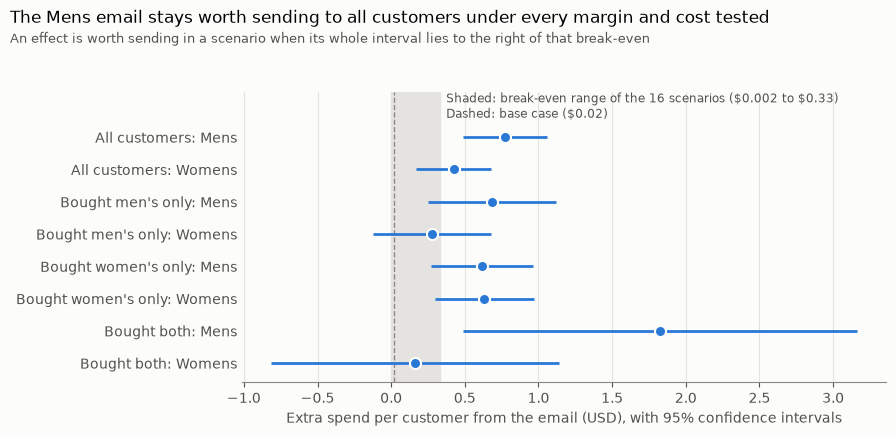

In [6]:
BLUE, GRAY, INK = "#2a78d6", "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "text.parse_math": False,
})

low_be, high_be = break_even.min().min(), break_even.max().max()
labels = [f"{customers}: {email}" for customers, email in estimates.index]
positions = np.arange(len(estimates))

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.axvspan(low_be, high_be, color="#e4e3df", zorder=0)
ax.axvline(BASE[1] / BASE[0], color=GRAY, linewidth=1, linestyle="--", zorder=1)
ax.hlines(positions, estimates["ci_low"], estimates["ci_high"], color=BLUE, linewidth=2, zorder=2)
ax.plot(estimates["estimate"], positions, "o", color=BLUE, markersize=8, markeredgecolor="#fcfcfb",
        markeredgewidth=1.5, zorder=3)
ax.text(high_be + 0.04, -0.95, f"Shaded: break-even range of the 16 scenarios (${low_be:.3f} to ${high_be:.2f})\n"
        "Dashed: base case ($0.02)", fontsize=8.5, color=INK, va="center")
ax.set_yticks(positions, labels=labels)
ax.tick_params(axis="y", length=0)
ax.set_ylim(len(estimates) - 0.4, -1.4)
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Extra spend per customer from the email (USD), with 95% confidence intervals")
fig.suptitle("The Mens email stays worth sending to all customers under every margin and cost tested", x=0.01, ha="left", fontsize=12)
fig.text(0.01, 0.905, "An effect is worth sending in a scenario when its whole interval lies to the right of that break-even",
         ha="left", fontsize=9, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig("../reports/figures/profit_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** **the two intervals that reach below zero, the Womens email for buyers of men's only and of both lines, are uncertain even at the base case.** The other intervals become uncertain only where their lower end falls inside the shaded band, which happens at \$0.10 per email.

**Summary of stage 06: no answer changes.** The Mens email pays under every margin and cost tested, so the answers to questions 3, 4 and 8 stand: send the Mens email to a random 10,000, avoid suppressing or suppress at random, and send the Mens email to all three audiences, with the Womens email only for women's-only buyers if it must be used.